In [33]:
import torch
import torch.nn

from laya.pretrained_rlcd import pretrain_rlcd_step
from laya.pretrained import PretrainedDecisionModel

from laya.dataset import (
    encode_decision_batch,
    raw_examples,
    build_decision_examples,
    move_batch_to_device,
    LABELS,
)

from laya.sft import evaluate
from laya.decision_reward import downstream_reward


from transformers import AutoTokenizer
import matplotlib.pyplot as plt

import random

device = "cpu"

In [34]:
model_name = "bert-base-uncased"

In [35]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [36]:
examples = build_decision_examples(raw_examples, LABELS, seed=42)

In [37]:
# train valid split

rng = random.Random(123)

indices = list(range(len(examples)))
rng.shuffle(indices)

cut = 48
train_indices = indices[:cut]
validate_indices = indices[cut:]

train_examples = [examples[e] for e in train_indices]
validate_examples = [examples[e] for e in validate_indices]

In [38]:
train_batch = encode_decision_batch(train_examples, tokenizer)
validate_batch = encode_decision_batch(validate_examples, tokenizer)

train_targets = torch.tensor(
    [e["target"] for e in train_examples], dtype=torch.long
).to(device)
validate_targets = torch.tensor(
    [e["target"] for e in validate_examples], dtype=torch.long
).to(device)

train_batch = move_batch_to_device(train_batch, device)
validate_batch = move_batch_to_device(validate_batch, device)

### decision head only


In [39]:
rlcd_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
rlcd_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21049.26it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [40]:
for para in rlcd_model.backbone.parameters():
    para.requires_grad = False

optimizer = torch.optim.AdamW(rlcd_model.decision_head.parameters(), lr=1e-5)

baseline


In [41]:
before_loss, before_accuracy, before_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
before_utility = downstream_reward(before_proba, validate_targets).mean().item()
before_loss, before_accuracy, before_utility, before_proba

(1.7698965072631836,
 0.5833333134651184,
 -0.3750000298023224,
 tensor([[4.7702e-04, 4.4586e-04, 4.5188e-04, 9.9863e-01, 0.0000e+00, 0.0000e+00],
         [5.2739e-02, 5.5385e-02, 8.9188e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.3024e-03, 3.2386e-03, 9.9346e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [5.1352e-03, 2.2834e-03, 2.2812e-03, 9.9030e-01, 0.0000e+00, 0.0000e+00],
         [3.5174e-01, 3.1412e-01, 3.3414e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.5854e-01, 1.5075e-01, 1.6356e-01, 1.7515e-01, 1.5200e-01, 0.0000e+00],
         [6.1146e-01, 4.2347e-05, 4.2272e-05, 4.3465e-05, 3.8841e-01, 0.0000e+00],
         [8.3473e-05, 9.9962e-01, 7.3866e-05, 7.3334e-05, 7.2293e-05, 7.9326e-05],
         [8.9849e-05, 9.9977e-01, 6.8903e-05, 6.9279e-05, 0.0000e+00, 0.0000e+00],
         [3.4996e-01, 5.0925e-01, 9.1266e-02, 4.9525e-02, 0.0000e+00, 0.0000e+00],
         [2.4849e-01, 2.6293e-01, 2.4993e-01, 2.3864e-01, 0.0000e+00, 0.0000e+00],
         [9.9975e-01, 8

train


In [42]:
rlcd_loss_history = []
rlcd_reward_history = []

n_steps = 200

for step in range(n_steps):
    loss, reward = pretrain_rlcd_step(
        rlcd_model,
        optimizer,
        train_batch["input_ids"],
        train_batch["attention_mask"],
        train_batch["option_marker_mask"],
        train_targets,
        n_candidates=32,
        exploration_std=0.2,
        scoring_weight=0.5,
    )
    rlcd_loss_history.append(loss)
    rlcd_reward_history.append(reward)

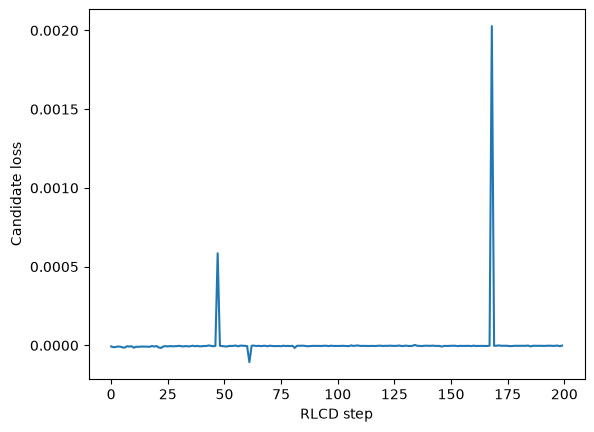

In [43]:
plt.figure()

plt.plot(
    rlcd_loss_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Candidate loss")

plt.show()

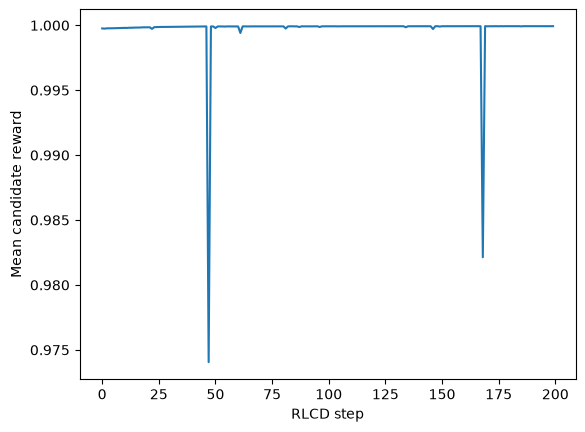

In [44]:
plt.figure()

plt.plot(
    rlcd_reward_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Mean candidate reward")

plt.show()

In [45]:
after_loss, after_accuracy, after_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
after_utility = downstream_reward(after_proba, validate_targets).mean().item()
after_loss, after_accuracy, after_utility, after_proba

(1.9233299493789673,
 0.5833333134651184,
 -0.3750000298023224,
 tensor([[1.6731e-04, 1.5776e-04, 1.5995e-04, 9.9951e-01, 0.0000e+00, 0.0000e+00],
         [4.2327e-02, 4.3464e-02, 9.1421e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [1.7093e-03, 1.6688e-03, 9.9662e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [2.4934e-03, 1.0982e-03, 1.0999e-03, 9.9531e-01, 0.0000e+00, 0.0000e+00],
         [3.5444e-01, 3.1142e-01, 3.3414e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.6521e-01, 1.5026e-01, 1.6173e-01, 1.7130e-01, 1.5150e-01, 0.0000e+00],
         [6.3784e-01, 1.0860e-05, 1.0884e-05, 1.1090e-05, 3.6213e-01, 0.0000e+00],
         [2.0549e-05, 9.9991e-01, 1.7971e-05, 1.7892e-05, 1.7547e-05, 1.8971e-05],
         [2.2686e-05, 9.9994e-01, 1.7315e-05, 1.7432e-05, 0.0000e+00, 0.0000e+00],
         [3.4949e-01, 5.2964e-01, 7.8813e-02, 4.2054e-02, 0.0000e+00, 0.0000e+00],
         [2.5031e-01, 2.6064e-01, 2.5023e-01, 2.3881e-01, 0.0000e+00, 0.0000e+00],
         [9.9994e-01, 2

### full model


In [46]:
rlcd_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
rlcd_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19500.19it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [47]:
for para in rlcd_model.backbone.parameters():
    para.requires_grad = True

optimizer = torch.optim.AdamW(
    [
        {
            "params": rlcd_model.backbone.parameters(),
            "lr": 1e-6,
        },
        {
            "params": rlcd_model.decision_head.parameters(),
            "lr": 1e-5,
        },
    ]
)

train


In [48]:
rlcd_loss_history = []
rlcd_reward_history = []

n_steps = 200

for step in range(n_steps):
    loss, reward = pretrain_rlcd_step(
        rlcd_model,
        optimizer,
        train_batch["input_ids"],
        train_batch["attention_mask"],
        train_batch["option_marker_mask"],
        train_targets,
        n_candidates=32,
        exploration_std=0.2,
        scoring_weight=0.5,
    )
    rlcd_loss_history.append(loss)
    rlcd_reward_history.append(reward)

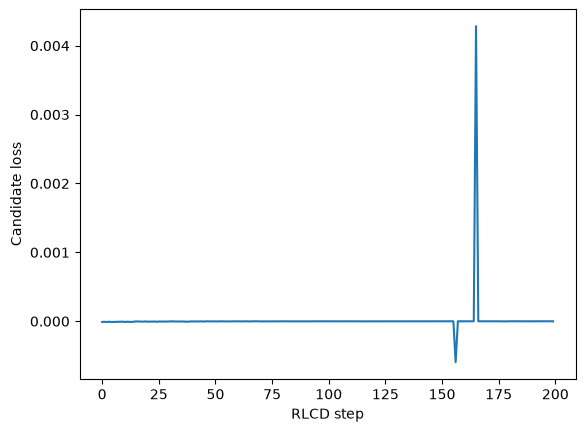

In [49]:
plt.figure()

plt.plot(
    rlcd_loss_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Candidate loss")

plt.show()

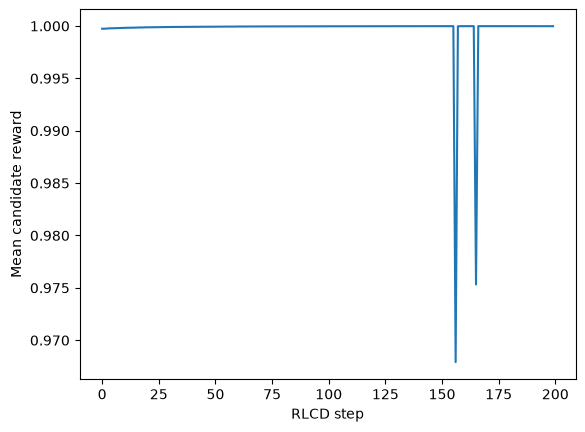

In [50]:
plt.figure()

plt.plot(
    rlcd_reward_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Mean candidate reward")

plt.show()

In [51]:
after_loss, after_accuracy, after_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
after_utility = downstream_reward(after_proba, validate_targets).mean().item()
after_loss, after_accuracy, after_utility, after_proba

(2.680234670639038,
 0.4166666567325592,
 -0.7916667461395264,
 tensor([[1.6547e-03, 1.5817e-03, 1.5934e-03, 9.9517e-01, 0.0000e+00, 0.0000e+00],
         [2.8043e-01, 2.6847e-01, 4.5110e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [1.3120e-04, 1.2935e-04, 9.9974e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [2.8995e-01, 2.1461e-01, 2.1744e-01, 2.7800e-01, 0.0000e+00, 0.0000e+00],
         [2.8419e-01, 2.6295e-01, 4.5286e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [9.9986e-01, 3.5131e-05, 3.6198e-05, 3.6985e-05, 3.5763e-05, 0.0000e+00],
         [9.9963e-01, 5.1160e-06, 5.0648e-06, 5.1366e-06, 3.5658e-04, 0.0000e+00],
         [5.8844e-06, 9.9997e-01, 5.5917e-06, 5.5222e-06, 5.4373e-06, 5.8391e-06],
         [7.0058e-06, 9.9998e-01, 5.8361e-06, 5.8665e-06, 0.0000e+00, 0.0000e+00],
         [3.3102e-01, 3.1456e-01, 1.8917e-01, 1.6526e-01, 0.0000e+00, 0.0000e+00],
         [2.5507e-01, 2.4958e-01, 2.5106e-01, 2.4429e-01, 0.0000e+00, 0.0000e+00],
         [9.9997e-01, 1.

In [52]:
# save checkpoint
torch.save(rlcd_model.state_dict(), "../model/rlcd_model.pt")